# Ring of floating transmons with nearest-neighbour coupling

`ring(n, side_um, pad_radius_um, idc)` builds **N** `CircTransmonFloating`
qubits on the vertices of a regular N-gon, each joined to its two neighbours
by a `CapNInterdigitalRound` coupler. Every transmon is turned **tangent to
the ring**, so one half-island faces the next neighbour and the other faces
the previous one; the split gap ends up `180/N` deg off each bond, inside
the island's usable arc.

* `n` -- number of transmons (`>= 4`). `n = 6` is the hexagon.
* `side_um` -- vertex spacing. `None` = the value that makes each coupler's
  tangent flare just overlap the two rims; a number stretches / squeezes the
  lattice (with a warning if the flare then misses).
* `pad_radius_um` -- half-island disc radius (transmon and coupler kept in sync).
* `idc` -- fill each split with the interdigitated shunt capacitor.

Blue = metal, red hatch = ground cutout, green = junction. No FEM here.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from build_design import ring, hexagon, matched_side_um, _design_bounds_mm
from render_geometry import render, sanity_checks


def show(design, title, figsize=(9, 9), pad=0.03):
    fig, ax = plt.subplots(figsize=figsize)
    render(design, ax)
    mnx, mny, mxx, mxy = _design_bounds_mm(design)
    ax.set_xlim(mnx - pad, mxx + pad)
    ax.set_ylim(mny - pad, mxy + pad)
    ax.set_title(title)
    ax.grid(alpha=0.15)
    plt.show()

## 1. The hexagon (n = 6)

metal nets (>300 um2): 12   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 2   [want 1 = fully connected]
components: ['Q0', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'c0_1', 'c1_2', 'c2_3', 'c3_4', 'c4_5', 'c5_0']
junctions : 6


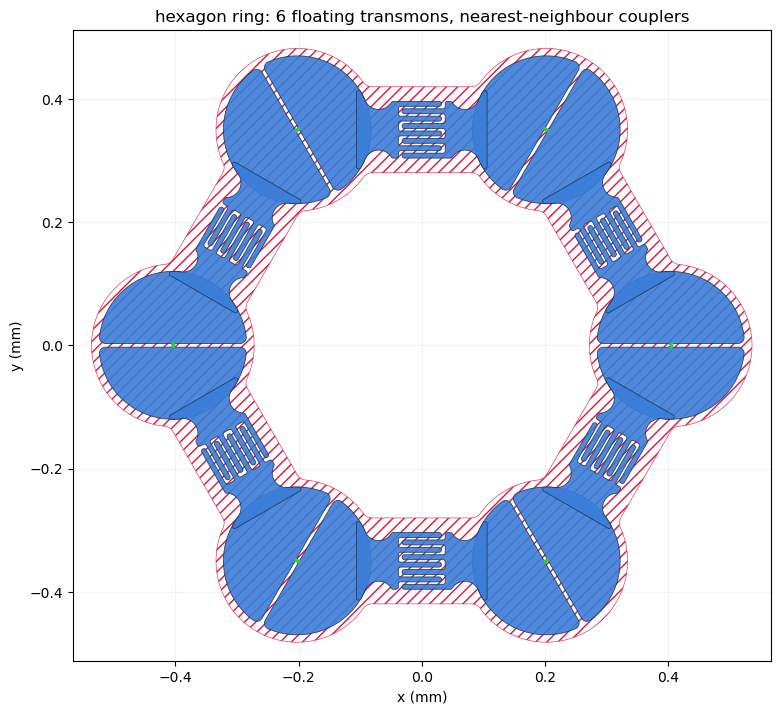

In [2]:
d6 = hexagon()
sanity_checks(d6)
print("components:", list(d6.components.keys()))
print("junctions :", len(d6.qgeometry.tables["junction"]))
show(d6, "hexagon ring: 6 floating transmons, nearest-neighbour couplers")

`sanity_checks` reports **2 ground pieces** -- the inner ground plane (the
polygon enclosed by the ring) is cut off from the outer one by the ring of
coupler moats. That is inherent to a closed loop of couplers, not a layout
bug; see section 5 for how the two are tied together in simulation.

The `2*N` metal nets are the two half-islands of each transmon; each coupler
comb overlaps (galvanically joins) one island, so the couplers do not add
nets. The min gap is the JJ / island gap.

### zoom on one vertex + its two couplers

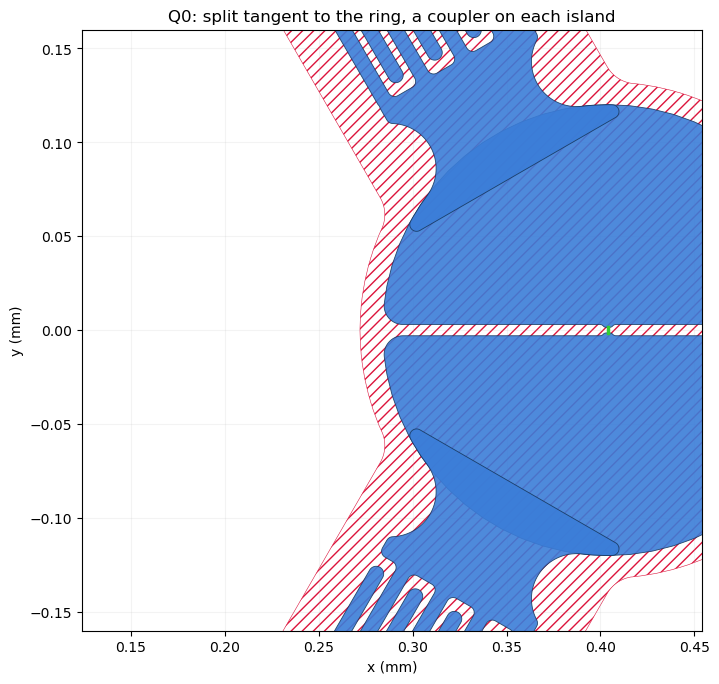

In [3]:
import numpy as np

q0 = d6.components["Q0"]
cx = float(str(q0.options["pos_x"]).replace("um", "")) * 1e-3
cy = float(str(q0.options["pos_y"]).replace("um", "")) * 1e-3
fig, ax = plt.subplots(figsize=(8, 8))
render(d6, ax)
ax.set_xlim(cx - 0.28, cx + 0.05)
ax.set_ylim(cy - 0.16, cy + 0.16)
ax.set_title("Q0: split tangent to the ring, a coupler on each island")
ax.grid(alpha=0.15)
plt.show()

## 2. Any N

`n >= 4`. Each bond sits `180/n` deg off the facing island's axis; at `n = 3`
that 60 deg swings the coupler flare over the split and shorts the two
half-islands, so the builder rejects it.

metal nets (>300 um2): 8   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 2   [want 1 = fully connected]


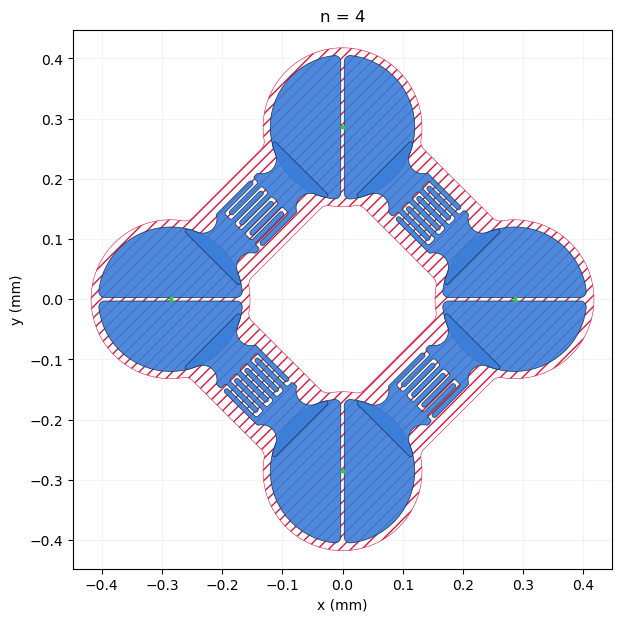

metal nets (>300 um2): 10   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 2   [want 1 = fully connected]


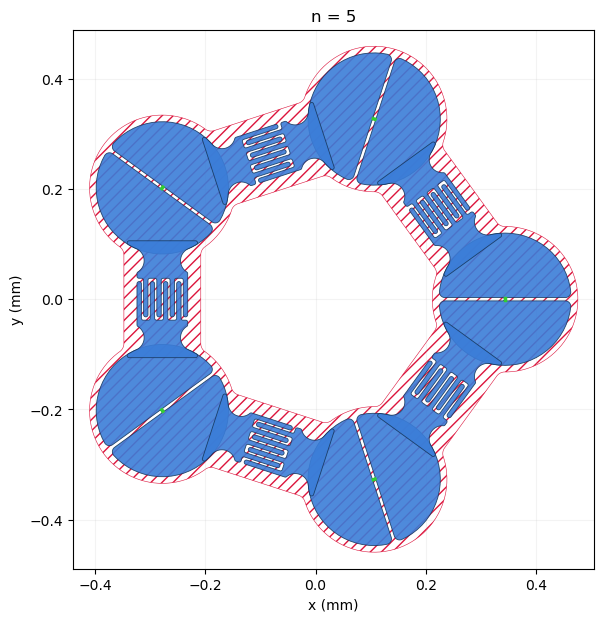

metal nets (>300 um2): 14   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 2   [want 1 = fully connected]


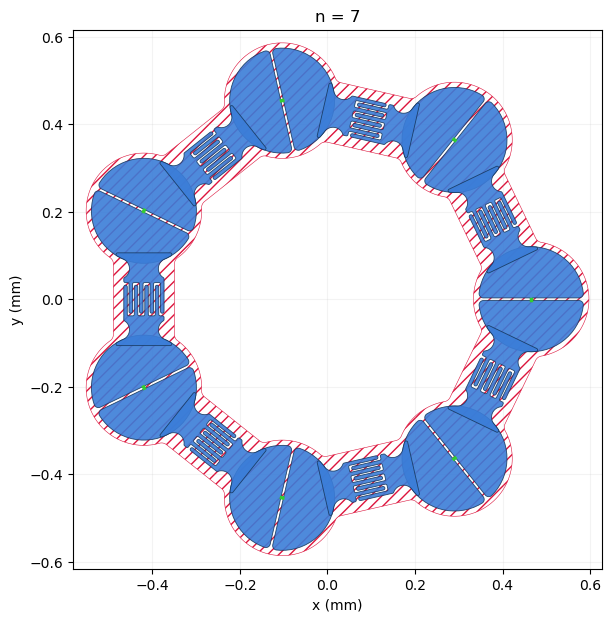

metal nets (>300 um2): 16   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 2   [want 1 = fully connected]


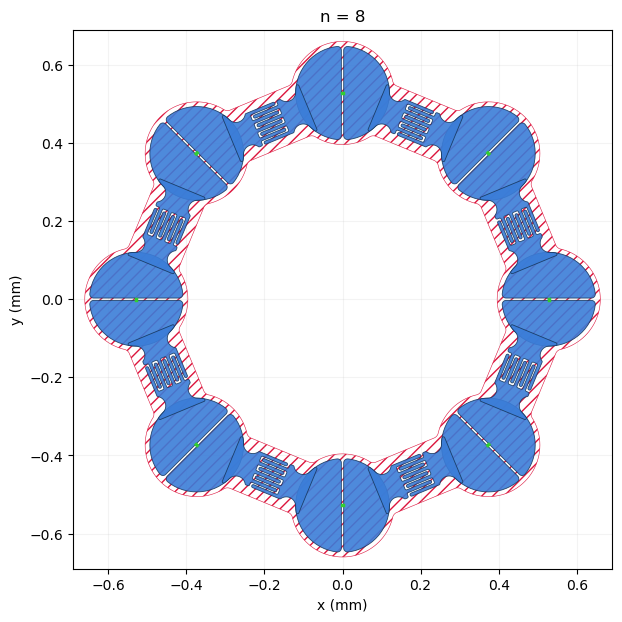

In [4]:
for n in (4, 5, 7, 8):
    d = ring(n)
    sanity_checks(d)
    show(d, f"n = {n}", figsize=(7, 7))

## 3. Side length

`side_um=None` uses `matched_side_um()` -- the spacing at which each coupler's
flare tip overlaps the rims by `ABUT_OVERLAP_UM`. Push it away from that and
the builder warns; the coupler geometry itself is unchanged, only the lattice
constant moves, so far off-match the flare either falls short of the rim
(open) or buries too deep.

matched side = 404.0 um


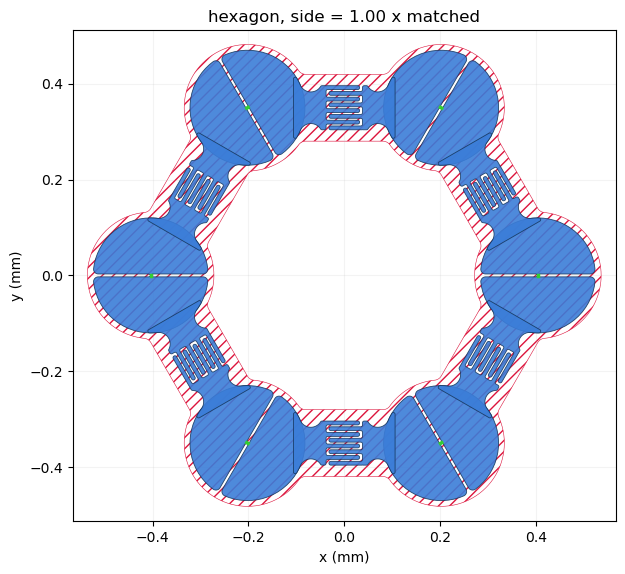

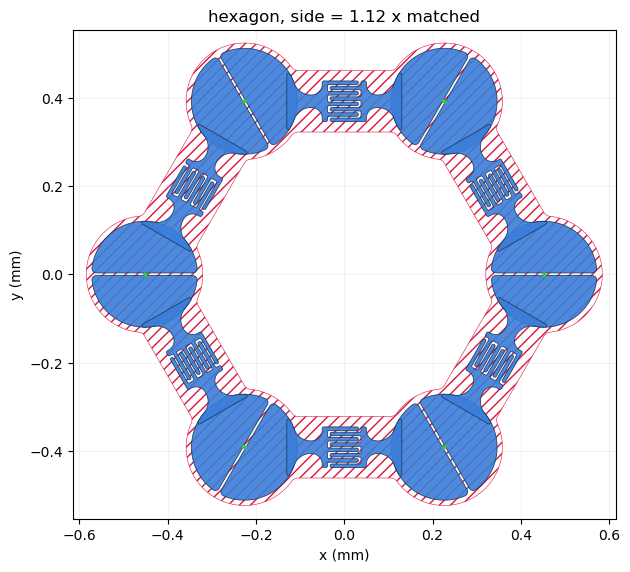

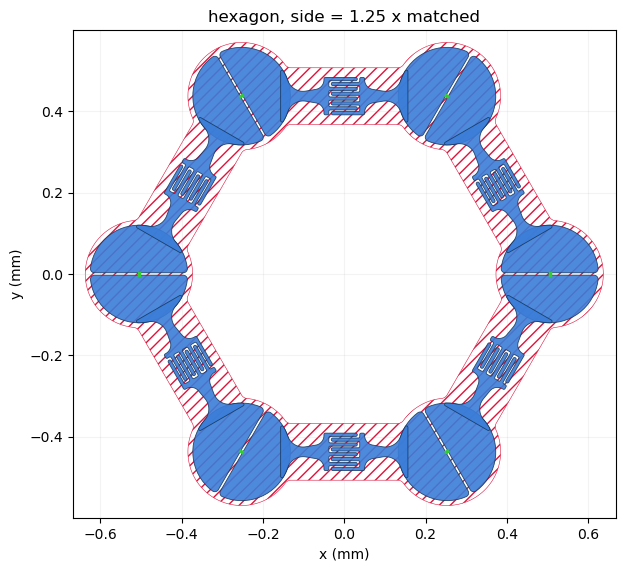

In [5]:
s0 = matched_side_um()
print(f"matched side = {s0:.1f} um")
for f in (1.0, 1.12, 1.25):
    show(ring(6, side_um=f * s0), f"hexagon, side = {f:.2f} x matched", figsize=(7, 7))

## 4. With the interdigitated shunt capacitor

metal nets (>300 um2): 12   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 2   [want 1 = fully connected]


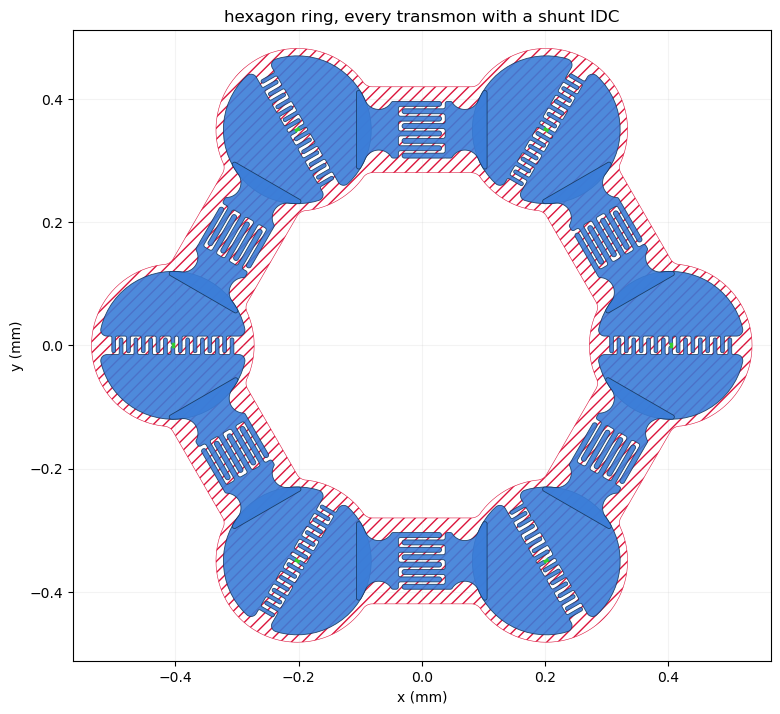

In [6]:
d_idc = ring(6, idc=True)
sanity_checks(d_idc)
show(d_idc, "hexagon ring, every transmon with a shunt IDC")

## 5. Connecting the inner and outer ground plane in simulation

The ring of couplers splits the ground metal into an **inner** plate (inside
the loop) and an **outer** plate. On the real chip they are tied together by a
**bond wire** (or an airbridge over one coupler) -- a DC short. In a solver you
impose the same short *without drawing the wire*:

* **Capacitance matrix / LOM** (Palace electrostatic, Ansys Q3D):
  assign **both** ground polygons to the *same* conductor / net / terminal.
  They collapse into one column of the Maxwell matrix = the reference node.
  In the `parametric_coupling` `Chip`, ground is already the implicit
  reference -- just do not give the inner plate its own node.
* **Eigenmode** (Palace, HFSS): both plates as PEC, plus **one lumped RLC
  boundary with R = 0** (or a tiny L) bridging a short segment between them --
  the numerical bond wire. Without it an isolated PEC plate is a DC
  equipotential but still floats at RF and carries a spurious ring / slotline
  mode. One tie is enough; a few spread around the ring push that mode well
  out of band.
* **SQDMetal / Palace wrappers**: the ground plane is one named region. If the
  layout splits it, either union it in the GDS (a thin connecting sliver) or
  list both surfaces under the `ground` / PEC attribute in the sim config.
* **Physical layout**: the drawn form of the bond wire is an **airbridge /
  crossover** over a coupler (metal on a raised bridge layer, landing on inner
  ground on one side and outer ground on the other). A coplanar strap cannot
  do it here -- it would have to cross the interdigitated fingers and short the
  combs.

The helper below labels the two ground pieces so you can pick the two
surfaces to tie together in whichever tool you export to.

2 ground plate(s): 1317899 um^2, 250490 um^2


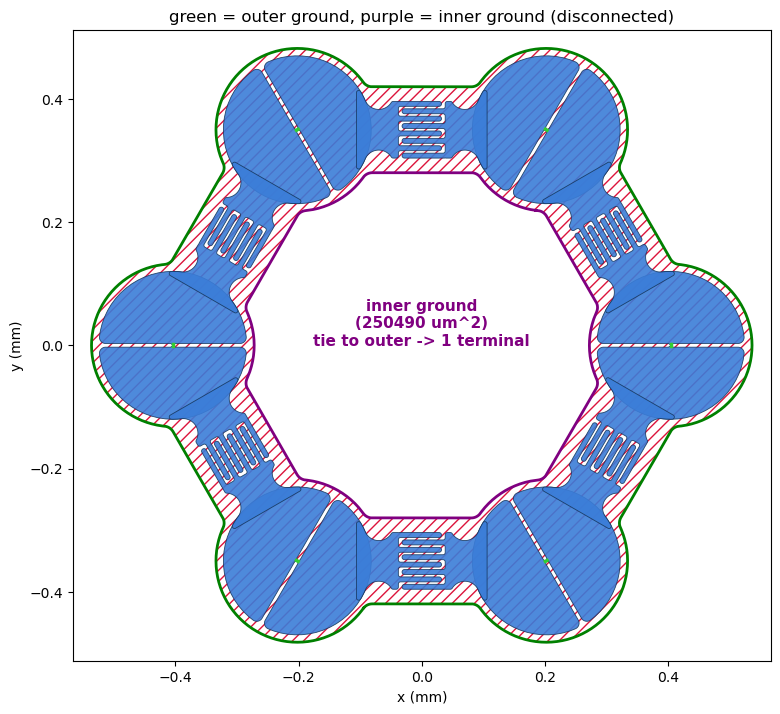

In [7]:
import numpy as np
from shapely.ops import unary_union
from shapely.geometry import box as _box


def ground_pieces(design):
    """Ground-plane polygons, largest first (the chip sheet minus every
    subtract=True poly). >1 means the plane is cut into disconnected plates."""
    p = design.qgeometry.tables["poly"]
    sub = p["subtract"].astype(bool)
    s = design.chips.main.size
    sx, sy = float(s.size_x[:-2]), float(s.size_y[:-2])
    cx, cy = float(s.center_x[:-2]), float(s.center_y[:-2])
    sheet = _box(cx - sx / 2, cy - sy / 2, cx + sx / 2, cy + sy / 2)
    g = sheet.difference(unary_union(list(p[sub]["geometry"])))
    return sorted((x for x in getattr(g, "geoms", [g]) if x.area > 1e-7),
                  key=lambda x: -x.area)


pieces = ground_pieces(d6)
print(f"{len(pieces)} ground plate(s):",
      ", ".join(f"{gp.area * 1e6:.0f} um^2" for gp in pieces))

fig, ax = plt.subplots(figsize=(9, 9))
render(d6, ax)
# outline every ground plate; the small (inner) one is the one that needs tying
cols = ["green"] + ["purple"] * (len(pieces) - 1)
for gp, col in zip(pieces, cols):
    for ring_ in [gp.exterior, *gp.interiors]:
        ax.plot(*ring_.xy, color=col, lw=2, zorder=5)
for gp, name, col in zip(pieces[1:], ("inner ground",), ("purple",)):
    c = gp.representative_point()
    ax.annotate(f"{name}\n({gp.area * 1e6:.0f} um^2)\ntie to outer -> 1 terminal",
                (c.x, c.y), color=col, ha="center", fontsize=11, fontweight="bold")
mnx, mny, mxx, mxy = _design_bounds_mm(d6)
ax.set_xlim(mnx - 0.03, mxx + 0.03)
ax.set_ylim(mny - 0.03, mxy + 0.03)
ax.set_title("green = outer ground, purple = inner ground (disconnected)")
plt.show()

## Interactive (MetalGUI)

Opens a **separate Qt window** (not inline). qiskit_metal routes every Qt
platform warning through its `metal` logger with a full stack trace -- cosmetic
noise under an offscreen / forwarded display -- so this cell quiets that logger
first. Skip it if you have no display.

In [8]:
import os, logging
logging.getLogger("metal").setLevel(logging.ERROR)

_disp = os.environ.get("DISPLAY", "") or os.environ.get("WAYLAND_DISPLAY", "")
if _disp and os.environ.get("QT_QPA_PLATFORM") == "offscreen":
    del os.environ["QT_QPA_PLATFORM"]

if not _disp:
    print("[!] no DISPLAY / WAYLAND_DISPLAY -- skipping MetalGUI. The inline plots "
          "above already show the geometry.")
else:
    get_ipython().run_line_magic("gui", "qt")
    from qiskit_metal import MetalGUI
    design = hexagon()
    gui = MetalGUI(design)
    gui.rebuild()
    gui.autoscale()

[!] no DISPLAY / WAYLAND_DISPLAY -- skipping MetalGUI. The inline plots above already show the geometry.
